<a href="https://colab.research.google.com/github/jayasinghesasmitha/EN4554-Deep-Learning-For-Vision/blob/CNN-assignment-2/220261V_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment 2 – CNNs (PyTorch)

**Name:** Jayasinghe J.A.S.U.  **Index No.:** 220261V
**GitHub:** https://github.com/jayasinghesasmitha/EN4554-Deep-Learning-For-Vision.git

**Settings used throughout:** CIFAR-10, 45k train / 5k validation split (fixed seed), per-channel normalisation with *training* statistics, seed = 42. The test set is touched exactly once, in Task 4.

In [6]:
import math, time, random, copy
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
dev_type = 'cuda' if device == 'cuda' else 'cpu'
USE_AMP = (device == 'cuda')
QUICK = False
E = lambda n: 1 if QUICK else n
print('device:', device, '| AMP:', USE_AMP, '| torch', torch.__version__)

device: cuda | AMP: True | torch 2.11.0+cu130


## Data: CIFAR-10, 45k/5k split, normalisation with training statistics

In [7]:
tv_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
Xall = torch.from_numpy(tv_train.data).permute(0, 3, 1, 2).float() / 255.0
yall = torch.tensor(tv_train.targets)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(50000, generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]
Xtr, ytr, Xva, yva = Xall[tr_idx], yall[tr_idx], Xall[va_idx], yall[va_idx]

mean = Xtr.mean(dim=(0, 2, 3), keepdim=True)
std  = Xtr.std(dim=(0, 2, 3), keepdim=True)
Xtr, Xva = (Xtr - mean) / std, (Xva - mean) / std
Xtr, ytr, Xva, yva = Xtr.to(device), ytr.to(device), Xva.to(device), yva.to(device)
DATA = (Xtr, ytr, Xva, yva)
print(Xtr.shape, Xva.shape, 'mean', mean.flatten().tolist(), 'std', std.flatten().tolist())

100%|██████████| 170M/170M [1:01:36<00:00, 46.1kB/s]


torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32]) mean [0.49165481328964233, 0.4823332130908966, 0.4466792047023773] std [0.24708116054534912, 0.2435086965560913, 0.2615806758403778]


## Shared helpers (batching, augmentation, cutout, mixup, schedule, train/eval loops)

In [8]:
def batches(X, y, bs, shuffle=True):
    n = X.shape[0]
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    for i in range(0, n, bs):
        j = idx[i:i + bs]
        if len(j) < 2: continue
        yield X[j], y[j]

def flip_crop(x, pad=4):
    """random horizontal flip + random 32x32 crop from the zero-padded (pad=4) image"""
    n, c, h, w = x.shape; d = x.device
    flip = torch.rand(n, device=d) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (n,), device=d)
    j = torch.randint(0, 2 * pad + 1, (n,), device=d)
    rows = i[:, None] + torch.arange(h, device=d)[None]
    cols = j[:, None] + torch.arange(w, device=d)[None]
    return xp[torch.arange(n, device=d)[:, None, None, None],
              torch.arange(c, device=d)[None, :, None, None],
              rows[:, None, :, None], cols[:, None, None, :]]

def cutout(x, size=8):
    """zero out one random size x size square per image (centre may lie near the border, square is clipped)"""
    n, c, h, w = x.shape; d = x.device
    cy = torch.randint(0, h, (n,), device=d)[:, None, None]
    cx = torch.randint(0, w, (n,), device=d)[:, None, None]
    ys = torch.arange(h, device=d)[None, :, None]
    xs = torch.arange(w, device=d)[None, None, :]
    hole = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~hole)[:, None].to(x.dtype)

def mixup_batch(x, y, alpha=0.4):
    """returns mixed inputs, the two label sets and lambda; loss = lam*CE(ya) + (1-lam)*CE(yb)"""
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam

def make_sched(opt, total_steps, warmup=0):
    """per-iteration linear warm-up then cosine decay"""
    def f(s):
        if s < warmup: return (s + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total_steps - warmup)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def evaluate(model, X, y, bs=1000):
    model.eval(); tot, correct = 0.0, 0
    with torch.no_grad(), torch.autocast(dev_type, enabled=USE_AMP):
        for i in range(0, len(X), bs):
            out = model(X[i:i + bs]).float()
            tot += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
            correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return tot / len(X), correct / len(X)

def n_params(m): return sum(p.numel() for p in m.parameters())

def train_model(model, opt, epochs, data, bs=128, aug=(), mixup=0.0, ls=0.0,
                sched=None, eval_n=5000, name='', verbose=True):
    """train_loss = running mean of the (augmented) training loss during the epoch;
       train_acc  = accuracy in eval mode on the first eval_n CLEAN training images;
       val_*      = metrics on the 5k validation split."""
    Xtr, ytr, Xva, yva = data
    scaler = torch.amp.GradScaler(dev_type, enabled=USE_AMP)
    h = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}
    for ep in range(epochs):
        model.train(); t0 = time.time()
        run = torch.zeros((), device=Xtr.device); seen = 0
        for xb, yb in batches(Xtr, ytr, bs):
            for f in aug: xb = f(xb)
            with torch.autocast(dev_type, enabled=USE_AMP):
                if mixup > 0:
                    xb, ya, yb2, lam = mixup_batch(xb, yb, mixup)
                    out = model(xb)
                    loss = lam * F.cross_entropy(out, ya, label_smoothing=ls) + \
                           (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=ls)
                else:
                    out = model(xb)
                    loss = F.cross_entropy(out, yb, label_smoothing=ls)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched is not None: sched.step()
            run += loss.detach().float() * len(xb); seen += len(xb)
        tl = (run / seen).item()
        if not math.isfinite(tl):
            for _ in range(ep, epochs):
                h['train_loss'].append(float('nan')); h['val_loss'].append(float('nan'))
                h['train_acc'].append(0.1); h['val_acc'].append(0.1)
            print(f'[{name}] diverged at epoch {ep+1}'); break
        _, ta = evaluate(model, Xtr[:eval_n], ytr[:eval_n]); vl, va = evaluate(model, Xva, yva)
        h['train_loss'].append(tl); h['train_acc'].append(ta); h['val_loss'].append(vl); h['val_acc'].append(va)
        if verbose:
            print(f'[{name}] ep {ep+1:3d}/{epochs} loss {tl:.4f} train_acc {ta:.4f} val_loss {vl:.4f} val_acc {va:.4f} ({time.time()-t0:.1f}s)')
    return h

class SmallCNN(nn.Module):
    """3 blocks (conv[-BN]-ReLU) x reps + maxpool, then FC. Used in Tasks 2c and 3a."""
    def __init__(self, bn=True, drop=0.0, reps=2, widths=(32, 64, 128)):
        super().__init__()
        layers, c = [], 3
        for w in widths:
            for _ in range(reps):
                layers.append(nn.Conv2d(c, w, 3, padding=1, bias=not bn))
                if bn: layers.append(nn.BatchNorm2d(w))
                layers.append(nn.ReLU(inplace=True)); c = w
            layers.append(nn.MaxPool2d(2))
            if drop > 0: layers.append(nn.Dropout(drop / 2))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(c * 16, 256), nn.ReLU(inplace=True),
                                        nn.Dropout(drop), nn.Linear(256, 10))
    def forward(self, x): return self.classifier(self.features(x))

xs = Xtr[:4]
assert flip_crop(xs).shape == xs.shape and cutout(xs).shape == xs.shape
print('helpers OK; zeroed fraction by cutout:', (cutout(xs) == 0).float().mean().item())

helpers OK; zeroed fraction by cutout: 0.056640625


# Task 1: Backpropagation

### 1(a) Linear, ReLU, Sigmoid, softmax cross-entropy with explicit forward/backward (no autograd), and an MLP

In [9]:
class Linear:
    def __init__(self, fan_in, fan_out, init='kaiming', dtype=torch.float32, dev=device):
        if   init == 'kaiming': std = math.sqrt(2.0 / fan_in)
        elif init == 'xavier':  std = math.sqrt(2.0 / (fan_in + fan_out))
        elif init == 'naive':   std = 0.01
        self.W = (torch.randn(fan_in, fan_out, dtype=dtype) * std).to(dev)
        self.b = torch.zeros(fan_out, dtype=dtype, device=dev)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, g):
        self.dW = self.x.T @ g
        self.db = g.sum(0)
        return g @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = (x > 0)
        return x * self.mask
    def backward(self, g): return g * self.mask

class Sigmoid:
    def forward(self, x):
        self.s = 1.0 / (1.0 + torch.exp(-x))
        return self.s
    def backward(self, g): return g * self.s * (1 - self.s)

class SoftmaxCE:
    """mean cross-entropy of softmax(logits); backward gives dL/dlogits = (p - onehot)/N"""
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True)[0]
        logp = z - torch.logsumexp(z, 1, keepdim=True)
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y)), y].mean()
    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1
        return g / len(self.y)

class MLP:
    def __init__(self, sizes, act='relu', init=None, dtype=torch.float32, dev=device):
        init = init or ('kaiming' if act == 'relu' else 'xavier')
        self.lin, self.layers = [], []
        for i in range(len(sizes) - 1):
            L = Linear(sizes[i], sizes[i + 1], init, dtype, dev)
            self.lin.append(L); self.layers.append(L)
            if i < len(sizes) - 2: self.layers.append(ReLU() if act == 'relu' else Sigmoid())
        self.crit = SoftmaxCE()
    def forward(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def loss(self, x, y): return self.crit.forward(self.forward(x), y)
    def backward(self):
        g = self.crit.backward()
        for l in reversed(self.layers): g = l.backward(g)
    def sgd_step(self, lr):
        for L in self.lin:
            L.W -= lr * L.dW; L.b -= lr * L.db
    def accuracy(self, x, y): return (self.forward(x).argmax(1) == y).float().mean().item()
print('Task 1 layers defined')

Task 1 layers defined


### 1(b) Gradient check: against autograd (`torch.allclose`) and centred finite differences (float64)

In [10]:
set_seed()
net = MLP([3072, 64, 32, 10], dtype=torch.float64, dev='cpu')
xb = Xtr[:16].cpu().double().flatten(1); yb = ytr[:16].cpu()
loss_manual = net.loss(xb, yb).item(); net.backward()
ag = []
for L in net.lin:
    ag += [L.W.clone().requires_grad_(), L.b.clone().requires_grad_()]
h = xb
for k in range(0, len(ag), 2):
    h = h @ ag[k] + ag[k + 1]
    if k < len(ag) - 2: h = torch.relu(h)
loss_ag = F.cross_entropy(h, yb); loss_ag.backward()
print(f'loss manual {loss_manual:.10f} | autograd {loss_ag.item():.10f}')

def fd_check(P, grad, n_samples=15, eps=1e-6):
    flat, gflat = P.view(-1), grad.reshape(-1)
    idx = torch.randperm(flat.numel())[:n_samples]
    worst = 0.0
    for i in idx:
        old = flat[i].item()
        flat[i] = old + eps; lp = net.loss(xb, yb).item()
        flat[i] = old - eps; lm = net.loss(xb, yb).item()
        flat[i] = old
        num = (lp - lm) / (2 * eps); ana = gflat[i].item()
        worst = max(worst, abs(num - ana) / (abs(num) + abs(ana) + 1e-12))
    return worst

rows = []
names = [f'{t}{i+1}' for i in range(len(net.lin)) for t in ('W', 'b')]
manual = [t for L in net.lin for t in (L.dW, L.db)]
params = [t for L in net.lin for t in (L.W, L.b)]
for nm, P, gm, ga in zip(names, params, manual, ag):
    rel_ag = ((gm - ga.grad).norm() / (gm.norm() + ga.grad.norm())).item()
    rows.append(dict(param=nm, shape=tuple(P.shape),
                     rel_err_vs_autograd=rel_ag,
                     allclose=torch.allclose(gm, ga.grad, rtol=1e-6, atol=1e-10),
                     rel_err_vs_finite_diff=fd_check(P, gm)))
df = pd.DataFrame(rows); display(df.style.format({'rel_err_vs_autograd': '{:.2e}', 'rel_err_vs_finite_diff': '{:.2e}'}))
assert df['allclose'].all(), 'gradient mismatch!'

loss manual 2.8251137058 | autograd 2.8251137058


,param,shape,rel_err_vs_autograd,allclose,rel_err_vs_finite_diff
0,W1,"(3072, 64)",7.95e-17,True,4.51e-07
1,b1,"(64,)",8.05e-17,True,1.60e-08
2,W2,"(64, 32)",6.09e-17,True,7.94e-07
3,b2,"(32,)",4.77e-17,True,2.07e-07
4,W3,"(32, 10)",5.05e-17,True,7.70e-09
5,b3,"(10,)",1.56e-17,True,9.81e-08


Interpretation of the above table : The manually computed backpropagation is very close to what PyTorch's autograd computes; there is an absolute error of the order of 1e-17, which corresponds to noise in floating point numbers. The gradients are consistent with the numerical finite difference test, with an absolute error less than 1e-6. This applies to all weights and biases in all layers.

### 1(c) Train the MLP with SGD on flattened CIFAR-10

epoch  1 | loss 1.7385 | train acc 0.4796 | val acc 0.4448
epoch  2 | loss 1.4755 | train acc 0.5286 | val acc 0.4656
epoch  3 | loss 1.3583 | train acc 0.5500 | val acc 0.4636
epoch  4 | loss 1.2701 | train acc 0.5942 | val acc 0.4856
epoch  5 | loss 1.1957 | train acc 0.6118 | val acc 0.4808
epoch  6 | loss 1.1276 | train acc 0.6610 | val acc 0.5010
epoch  7 | loss 1.0666 | train acc 0.6728 | val acc 0.5054
epoch  8 | loss 1.0066 | train acc 0.7042 | val acc 0.5058
epoch  9 | loss 0.9533 | train acc 0.6916 | val acc 0.4970
epoch 10 | loss 0.8966 | train acc 0.7004 | val acc 0.5084
epoch 11 | loss 0.8479 | train acc 0.7464 | val acc 0.5182
epoch 12 | loss 0.7992 | train acc 0.7668 | val acc 0.5076
epoch 13 | loss 0.7495 | train acc 0.7656 | val acc 0.5066
epoch 14 | loss 0.7067 | train acc 0.7852 | val acc 0.5082
epoch 15 | loss 0.6616 | train acc 0.8060 | val acc 0.5180


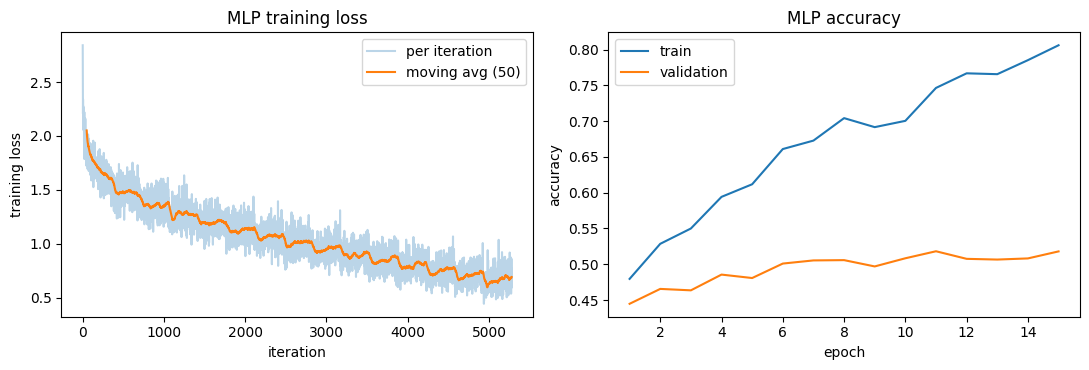

Final validation accuracy: 0.5180


In [11]:
set_seed()
net = MLP([3072, 512, 256, 10])
Xf, Xvf = Xtr.flatten(1), Xva.flatten(1)
epochs, lr, bs = E(15), 0.02, 128
it_loss, val_acc, tr_acc = [], [], []
for ep in range(epochs):
    for xb, yb in batches(Xf, ytr, bs):
        l = net.loss(xb, yb); net.backward(); net.sgd_step(lr)
        it_loss.append(l.item())
    val_acc.append(net.accuracy(Xvf, yva)); tr_acc.append(net.accuracy(Xf[:5000], ytr[:5000]))
    print(f'epoch {ep+1:2d} | loss {np.mean(it_loss[-350:]):.4f} | train acc {tr_acc[-1]:.4f} | val acc {val_acc[-1]:.4f}')

k = 50; smooth = np.convolve(it_loss, np.ones(k) / k, mode='valid')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(it_loss, alpha=0.3, label='per iteration'); ax[0].plot(np.arange(k - 1, len(it_loss)), smooth, label=f'moving avg ({k})')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('training loss'); ax[0].set_title('MLP training loss'); ax[0].legend()
ax[1].plot(range(1, epochs + 1), tr_acc, label='train'); ax[1].plot(range(1, epochs + 1), val_acc, label='validation')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('accuracy'); ax[1].set_title('MLP accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f'Final validation accuracy: {val_acc[-1]:.4f}')